[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/12-fronteiras-de-decisao.ipynb)

# Fronteiras de decisao

Este caderno desenha a cerca dos dois classificadores em tres planos.

Dois planos sao sinteticos, gerados na hora pelo scikit-learn, e nao sao medida de nada:

- `make_blobs`: duas nuvens gaussianas, quase separaveis por uma reta.
- `make_moons`: duas luas. Uma reta corta as pontas da lua em vez de seguir o arco. O gaussiano de eixos alinhados faz uma concessao parecida, porque nao mistura os dois eixos. Com o ruido deste caderno os dois modelos ainda acertam a maior parte dos pontos; a figura mostra o pedaco que a cerca erra.

O terceiro plano e real: comprimento e largura da petala no Iris de Fisher/Anderson, via `load_iris`. Nuvem e lua nao devem ser citadas como dado biologico. A Iris deve.

Em todos os paineis os atributos entram padronizados, com media e desvio do treino. O Gaussiano usa `var_smoothing=1e-9`. A logistica usa $\lambda = 1/n$.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

A fronteira e o lugar em que o modelo troca de opiniao. Na regressao logistica binaria ela e a reta em que o escore z vale zero, porque a sigmoide de zero e um meio. No Naive Bayes gaussiano ela e o lugar em que as duas gaussianas, multiplicadas pelo prior, empatam. Gaussiana de eixos alinhados faz uma cerca curva, mas sem a inclinacao de uma elipse torta: os eixos do plano nao se misturam. Por isso uma lua, que pede mistura dos dois eixos, deixa pontas do lado errado da cerca, mesmo quando a maior parte dos pontos continua certa.


## 2) Fundamentação matemática

O teorema de Bayes inverte a pergunta. Em vez de perguntar so quao tipico e o texto dentro de uma classe, calculamos a chance da classe depois de ler o texto:

$$
P(y \mid x) = \frac{P(x \mid y)\, P(y)}{P(x)}
$$

- $P(y \mid x)$ e a probabilidade da classe $y$ depois de observar $x$. E a saida do classificador.
- $P(x \mid y)$ e a verossimilhanca: a chance de ver esse texto se a classe for $y$.
- $P(y)$ e o prior, a frequencia da classe antes de olhar o texto.
- $P(x)$ e a evidencia. Ela nao depende de $y$, entao nao muda qual classe ganha. Na hora de decidir, comparamos $P(x \mid y)\,P(y)$.

A hipotese de independencia condicional, a parte ingênua do nome, diz que, dada a classe, uma palavra nao informa a outra:

$$
P(x \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
$$

- $x_j$ e a contagem da palavra $j$.
- $d$ e o tamanho do vocabulario.
- O produto e falso em frases reais ("nao" muda "bom"), mas o erro muitas vezes se reparte e o sinal de cada palavra ainda aponta a classe certa.

No modelo multinomial a probabilidade de uma palavra e a fatia dela nas contagens da classe. A suavizacao de Laplace soma $\alpha$ para uma palavra nunca vista nao zerar o produto inteiro:

$$
\hat{P}(w \mid y) = \frac{n_{y,w} + \alpha}{n_y + \alpha \, |V|}
$$

- $n_{y,w}$ e quantas vezes a palavra $w$ apareceu na classe $y$.
- $n_y$ e a soma de todas as contagens da classe.
- $|V|$ e o numero de palavras do vocabulario.
- $\alpha$ e a forca da suavizacao. Com $\alpha = 1$ ha uma ocorrencia ficticia de cada palavra em cada classe.

Mil probabilidades pequenas, multiplicadas, estouram para zero no computador. O logaritmo transforma o produto em soma:

$$
\log P(y \mid x) \propto \log P(y) + \sum_{j=1}^{d} x_j \, \log \hat{P}(w_j \mid y)
$$

- $\log P(y)$ e o prior em escala de log.
- $x_j \log \hat{P}(w_j \mid y)$ pesa a palavra pela contagem dela neste texto. Palavra ausente entra com zero.
- A classe escolhida e a de maior soma. Para converter as somas em probabilidades que somam 1, subtraimos o log-sum-exp de todas as classes.


A regressao logistica desenha um escore linear e o espreme numa probabilidade. O escore e

$$
z = w^{\top} x + b
$$

- $x$ e o vetor de atributos da amostra.
- $w$ e o vetor de pesos, um por atributo.
- $b$ e o vies, o escore quando todos os atributos valem zero.
- $z$ e o logaritmo da chance, o log-odds: $\log \frac{p}{1-p} = z$.

A sigmoide converte $z$ na probabilidade da classe positiva:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- Se $z = 0$, $\sigma(z) = 0{,}5$.
- Se $z$ cresce, $\sigma(z)$ sobe em direcao a 1, sem nunca passar de 1.
- Se $z$ cai, $\sigma(z)$ desce em direcao a 0.
- A derivada $\sigma(z)\,(1-\sigma(z))$ e a que aparece no gradiente.

Com mais de duas classes, cada classe tem seu escore $z_k$ e a softmax divide as exponenciais:

$$
P(y = k \mid x) = \frac{e^{z_k}}{\sum_{c=1}^{K} e^{z_c}}
$$

- $z_k = w_k^{\top} x + b_k$ e o escore da classe $k$.
- $K$ e o numero de classes.
- O denominador faz as $K$ probabilidades somarem 1.
- Subtrair $\max_c z_c$ antes da exponencial nao muda o resultado e evita estouro numerico.

O treino minimiza a entropia cruzada, a surpresa media de ter previsto pouco a classe verdadeira, mais uma penalidade L2 so nos pesos:

$$
J(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big] + \frac{\lambda}{2}\|w\|^2
$$

- $n$ e o numero de amostras de treino.
- $y_i$ vale 1 na classe positiva e 0 na negativa.
- $\hat{p}_i = \sigma(w^{\top} x_i + b)$.
- $\lambda$ e o argumento `l2` do codigo. O vies $b$ nao entra em $\|w\|^2$: deslocar a fronteira nao deve ser punido do mesmo jeito que um peso enorme.
- No caso multiclasse, $y_i \log \hat{p}_i$ vira o log da probabilidade da classe correta.

A descida de gradiente anda no sentido em que $J$ diminui. Para a perda media acima, com a classe positiva codificada como 1:

$$
\frac{\partial J}{\partial w} = \frac{1}{n} X^{\top}(\hat{p} - y) + \lambda w, \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)
$$

- $\hat{p} - y$ e o erro de cada amostra. Positivo quando o modelo exagerou a classe 1.
- $X^{\top}(\hat{p}-y)/n$ aponta quais atributos empurraram esse erro.
- $\lambda w$ encolhe os pesos em direcao a zero.
- O passo e $w \leftarrow w - \eta \, \partial J/\partial w$, e $\eta$ e o `learning_rate`.

O `C` do scikit-learn penaliza a soma dos erros, nao a media. Com $C = 1$, o $\lambda$ equivalente nesta media e $1/n$. E o valor usado nos cadernos para a comparacao ser justa. O otimizador deles (lbfgs) nao e o nosso passo fixo, entao os pesos nao precisam coincidir casa decimal; a qualidade no teste e que precisa ficar perto.

No gaussiano, $\mu_{k,j}$ e $\sigma^2_{k,j}$ sao a media e a variancia do atributo $j$ na classe $k$. Nao ha covariancia entre atributos: a hipotese de independencia zera o termo cruzado. A logistica nao estima media nem variancia; ela estima $w$ e $b$. As duas familias desenham cercas diferentes no mesmo plano.


## 3) Visualização

Cada painel mostra os pontos de teste e a probabilidade da classe positiva (ou a classe prevista, no caso das tres Iris) segundo o modelo do zero. O titulo diz se o plano e sintetico ou se e a Iris.


duas nuvens | sintetico, gerado por codigo, nao e medicao


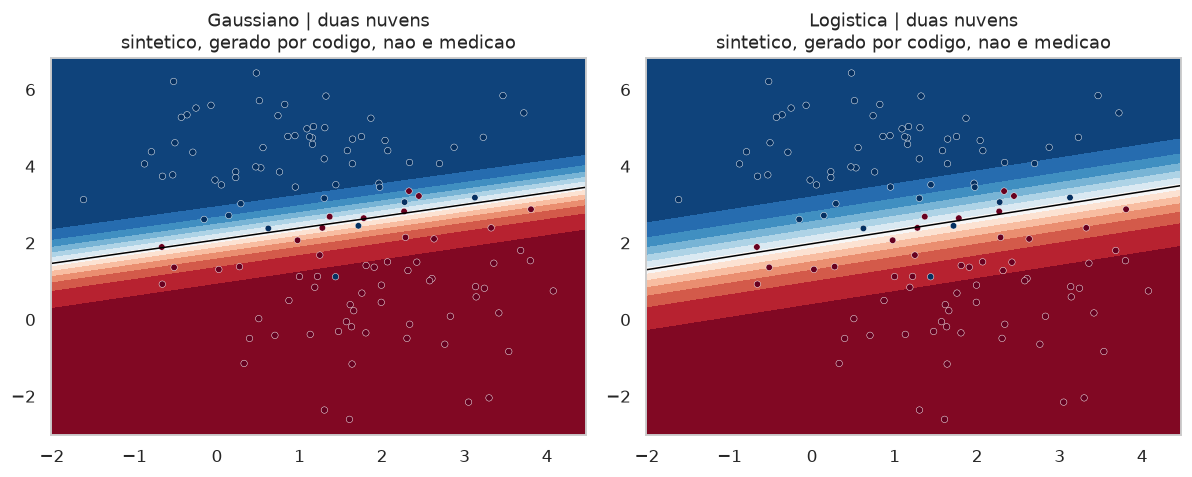

RESUMO_METRICAS {"conjunto": "duas nuvens", "sintetico": true, "f1_gaussiano": 0.9310344827586207, "f1_logistica": 0.9310344827586207, "roc_auc_gaussiano": 0.9894444444444445, "roc_auc_logistica": 0.9894444444444445}
sintetico, gerado por codigo, nao e medicao
duas luas | sintetico, gerado por codigo, nao e medicao


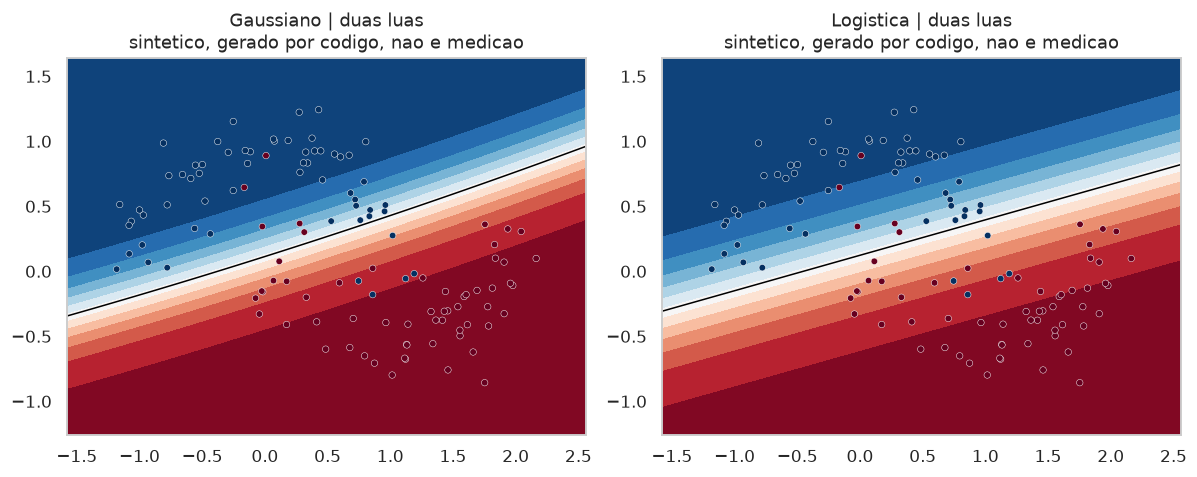

RESUMO_METRICAS {"conjunto": "duas luas", "sintetico": true, "f1_gaussiano": 0.9166666666666666, "f1_logistica": 0.9166666666666666, "roc_auc_gaussiano": 0.9555555555555556, "roc_auc_logistica": 0.955}
sintetico, gerado por codigo, nao e medicao
petalas de Iris | Iris real (load_iris)


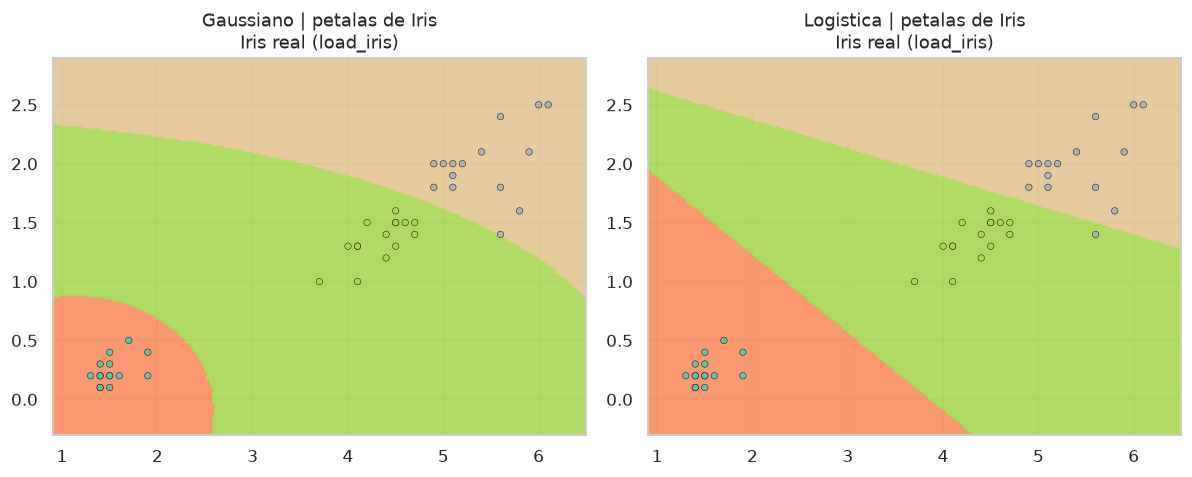

RESUMO_METRICAS {"conjunto": "petalas de Iris", "sintetico": false, "f1_macro_gaussiano": 1.0, "f1_macro_logistica": 0.9777530589543938, "acuracia_gaussiano": 1.0, "acuracia_logistica": 0.9777777777777777}
Iris real (load_iris)


{'conjunto': 'petalas de Iris',
 'sintetico': False,
 'f1_macro_gaussiano': 1.0,
 'f1_macro_logistica': 0.9777530589543938,
 'acuracia_gaussiano': 1.0,
 'acuracia_logistica': 0.9777777777777777}

In [2]:
from sklearn.datasets import load_iris, make_blobs, make_moons
from sklearn.model_selection import train_test_split

from mlalgos import GaussianNB, LogisticRegression
from mlalgos.metrics import f1_score, roc_auc_score

def desenhar(modelo, X_orig, y, media, desvio, ax, titulo, multiclasse=False):
    xx, yy = np.meshgrid(
        np.linspace(X_orig[:, 0].min() - 0.4, X_orig[:, 0].max() + 0.4, 200),
        np.linspace(X_orig[:, 1].min() - 0.4, X_orig[:, 1].max() + 0.4, 200),
    )
    grade = (np.column_stack([xx.ravel(), yy.ravel()]) - media) / desvio
    if multiclasse:
        campo = modelo.predict(grade).astype(float).reshape(xx.shape)
        ax.contourf(xx, yy, campo, levels=np.arange(-0.5, 3.5, 1), cmap="Set2", alpha=0.9)
        ax.scatter(X_orig[:, 0], X_orig[:, 1], c=y, cmap="Set2", edgecolor="black", s=18, linewidth=0.3)
    else:
        campo = modelo.predict_proba(grade)[:, 1].reshape(xx.shape)
        ax.contourf(xx, yy, campo, levels=12, cmap="RdBu_r")
        ax.contour(xx, yy, campo, levels=[0.5], colors="black", linewidths=1)
        ax.scatter(X_orig[:, 0], X_orig[:, 1], c=y, cmap="RdBu_r", edgecolor="white", s=18, linewidth=0.3)
    ax.set_title(titulo)

def painel(nome, X, y, sintetico, multiclasse=False):
    origem = "sintetico, gerado por codigo, nao e medicao" if sintetico else "Iris real (load_iris)"
    print(nome, "|", origem)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
    X_tr_p, X_te_p, media, desvio = padronizar(X_tr, X_te)
    nb = GaussianNB().fit(X_tr_p, y_tr)
    lr = LogisticRegression(learning_rate=1.0, n_iterations=800, l2=1.0 / len(X_tr_p)).fit(X_tr_p, y_tr)
    fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
    desenhar(nb, X_te, y_te, media, desvio, eixos[0], f"Gaussiano | {nome}\n{origem}", multiclasse)
    desenhar(lr, X_te, y_te, media, desvio, eixos[1], f"Logistica | {nome}\n{origem}", multiclasse)
    plt.tight_layout()
    plt.show()
    if multiclasse:
        from mlalgos.metrics import f1_score as f1m
        relatorio = {
            "conjunto": nome,
            "sintetico": sintetico,
            "f1_macro_gaussiano": f1m(y_te, nb.predict(X_te_p), average="macro"),
            "f1_macro_logistica": f1m(y_te, lr.predict(X_te_p), average="macro"),
            "acuracia_gaussiano": float(np.mean(nb.predict(X_te_p) == y_te)),
            "acuracia_logistica": float(np.mean(lr.predict(X_te_p) == y_te)),
        }
    else:
        relatorio = {
            "conjunto": nome,
            "sintetico": sintetico,
            "f1_gaussiano": f1_score(y_te, nb.predict(X_te_p), pos_label=1),
            "f1_logistica": f1_score(y_te, lr.predict(X_te_p), pos_label=1),
            "roc_auc_gaussiano": roc_auc_score(y_te, nb.predict_proba(X_te_p)[:, 1], pos_label=1),
            "roc_auc_logistica": roc_auc_score(y_te, lr.predict_proba(X_te_p)[:, 1], pos_label=1),
        }
    print("RESUMO_METRICAS " + json.dumps(relatorio))
    print(origem)
    return relatorio

X_blob, y_blob = make_blobs(n_samples=400, centers=2, cluster_std=1.15, random_state=0)
X_lua, y_lua = make_moons(n_samples=400, noise=0.18, random_state=0)
iris = load_iris()
X_iris, y_iris = iris.data[:, 2:4], iris.target

painel("duas nuvens", X_blob, y_blob, sintetico=True)
painel("duas luas", X_lua, y_lua, sintetico=True)
painel("petalas de Iris", X_iris, y_iris, sintetico=False, multiclasse=True)


## 4) Implementação do zero

O codigo da secao anterior ja ajustou `GaussianNB` e `LogisticRegression` do pacote `mlalgos`. Abaixo, um recorte so da nuvem, para inspecionar os parametros que a formula cita: media, variancia e pesos.


In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X_blob, y_blob, test_size=0.3, random_state=0, stratify=y_blob)
X_tr_p, X_te_p, _, _ = padronizar(X_tr, X_te)
nb = GaussianNB().fit(X_tr_p, y_tr)
lr = LogisticRegression(learning_rate=1.0, n_iterations=800, l2=1.0 / len(X_tr_p)).fit(X_tr_p, y_tr)
print("dados sinteticos de make_blobs, nao sao medicao")
print("medias por classe", nb.theta_)
print("variancias por classe", nb.var_)
print("pesos da logistica", lr.coef_, "vies", lr.intercept_)
print("concordancia entre os dois nesta nuvem", float(np.mean(nb.predict(X_te_p) == lr.predict(X_te_p))))


dados sinteticos de make_blobs, nao sao medicao
medias por classe [[-0.4393591   0.84523044]
 [ 0.4393591  -0.84523044]]
variancias por classe [[0.80292816 0.29949751]
 [0.810999   0.2716735 ]]
pesos da logistica [ 0.85255523 -4.20131552] vies -0.16328701155898345
concordancia entre os dois nesta nuvem 1.0


## 5) Implementação com scikit-learn

Na nuvem sintetica, o Gaussiano nosso e o do scikit-learn recebem a mesma matriz. As log-probabilidades devem coincidir.


In [4]:
from sklearn.naive_bayes import GaussianNB as SkGaussian

sk = SkGaussian().fit(X_tr_p, y_tr)
diferenca = np.max(np.abs(nb.predict_log_proba(X_te_p) - sk.predict_log_proba(X_te_p)))
print("maior diferenca absoluta de log-probabilidade", float(diferenca))
print("dados sinteticos de make_blobs")


maior diferenca absoluta de log-probabilidade 8.881784197001252e-16
dados sinteticos de make_blobs


## 6) Avaliação

Os tres resumos ja foram impressos na secao 3, cada um ao lado da propria figura, com o aviso de dado sintetico ou de Iris real. Aqui eles ficam reunidos. Nuvem e lua nao tem classe "verdadeira" fora do gerador: o rotulo e o que `make_blobs` e `make_moons` gravaram.


In [5]:
print("Releia os RESUMO_METRICAS acima. Nuvem e lua sao sinteticas. A Iris e a tabela real de petalas.")
print("Na lua o F1 fica um pouco abaixo do das nuvens: a cerca reta e a gaussiana de eixos alinhados nao seguem o arco, mas ainda classificam bem a maior parte deste desenho.")


Releia os RESUMO_METRICAS acima. Nuvem e lua sao sinteticas. A Iris e a tabela real de petalas.
Na lua o F1 fica um pouco abaixo do das nuvens: a cerca reta e a gaussiana de eixos alinhados nao seguem o arco, mas ainda classificam bem a maior parte deste desenho.


## 7) Desafios

1. Suba o `noise` de `make_moons` para 0,35. A AUC dos dois modelos cai juntas, ou uma cai antes?
2. Troque `cluster_std` das nuvens para 2,5. A fronteira ainda e uma reta nitida?
3. Na Iris, desenhe a fronteira sem padronizar. O Gaussiano muda mais do que a logistica? Lembre do `epsilon` amarrado a maior variancia.
